# KO7 — AlphaMissense Classifier Comparison for PDAC Detection and Molecular Subtyping

## Overview

This notebook compares 7 AlphaMissense-based classifiers across two classification tasks: distinguishing PDAC patients from healthy individuals (PvH, evaluated by AUPRC) and separating Classical from Basal-like molecular subtypes (CvB, evaluated by AUROC). Per-fold metric distributions from KO5 (AM threshold classifier) and KO6 (Biologically Validated LDA) are consolidated into a summary table and 2-panel boxplot.

## Data

**Input**
- `M1_G_subagging_cache.json` — KO5 subagging cache (PvH AM threshold, 100 × 5-fold CV).
- `M1_H_bootstrap_cache.json` — KO5 bootstrap cache (CvB AM threshold, 100 × 5-fold CV).
- `results/HvP_V2/LDA_KoCoFX_HvP_{binary,pathogenic}_cache.npz` — KO6 LDA OOF scores (PvH).
- `results/AM_CvB/{binary,pathogenic}_cvb_cache.npz` — KO6 LDA OOF scores (CvB).
- `results/AM_CvB/binary_cvb_apparent.npz` — KO6 LDA apparent scores (CvB, no CV).
- `merged_tcga_1000G.parquet` — merged cohort for PDAC prevalence (AUPRC baseline).

**Output**
- `../Figures/KO7_model_overview.{pdf,png,svg}` — 2-panel model comparison boxplot.

## Method

- **Per-fold metrics**: AUPRC (PvH) and AUROC (CvB) from KO5/KO6 caches; F1, Precision, Recall, Specificity via optimal F1 threshold on OOF scores per draw.
- **Resampling**: rows 1–3 subagging, rows 4–6 bootstrapping (both 100 × 5-fold CV, n = 500); row 7 apparent (100 draws, no CV, n = 100).
- **Summary**: median and 95 % CI (2.5th–97.5th percentile).
- **Visualisation**: Great Tables comparison table and 2-panel boxplot.

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup & Data Loading | Imports, colour palette, data paths, output directory; PDAC prevalence (AUPRC baseline) |
| 2 | Load Per-Fold Metric Arrays | Load AUPRC / AUROC arrays from KO5 caches and KO6 LDA OOF caches |
| 3 | Validation | Assert expected array sizes, finite values, and [0, 1] range |
| 4 | Summary Statistics | Median and 95 % CI per model |
| 5 | Per-Fold Classifier Metrics | Compute F1, Precision, Recall, Specificity from OOF scores |
| 6 | Comparison Table | Great Tables: all metrics across 7 models, grouped by task |
| 7 | Model Comparison Boxplot | 2-panel boxplot — PvH (AUPRC) and CvB (AUROC) |
| 8 | Statistical Significance | Effect sizes, Nadeau–Bengio corrected t-test, Mann–Whitney U, Holm–Bonferroni correction |

## 1. Setup & Data Loading

In [2]:
import json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from great_tables import GT, md as gtmd, style, loc

NETWORK_DATA = Path('/zfsdata/BRP_DF/data')
# LOCAL_DATA   = Path(r'C:/Users/daane/Desktop/DATA')
LOCAL_DATA   = Path(r'C:/2604_BRP/Data')
DATA_DIR     = NETWORK_DATA if NETWORK_DATA.exists() else LOCAL_DATA

RESULTS_HVP = DATA_DIR / 'results' / 'HvP_V2'
RESULTS_CVB = DATA_DIR / 'results' / 'AM_CvB'
KO5_G_CACHE = DATA_DIR / 'M1_G_subagging_cache.json'
KO5_H_CACHE = DATA_DIR / 'M1_H_bootstrap_cache.json'

WONG = {
    'orange':    '#E69F00',
    'sky_blue':  '#56B4E9',
    'green':     '#009E73',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
}

out_dir = Path('../Figures')
out_dir.mkdir(exist_ok=True)

print(f'DATA_DIR : {DATA_DIR}')
print(f'exists   : {DATA_DIR.exists()}')

DATA_DIR : C:\2604_BRP\Data
exists   : True


In [3]:
# Compute _prev_g_h: PDAC fraction in the HvP cohort.
# Used as the random-classifier AUPRC baseline in the left boxplot panel.
_merged   = pl.read_parquet(
    DATA_DIR / 'merged_tcga_1000G.parquet',
    columns=['source', 'sample_id'],
)
n_pdac    = _merged.filter(pl.col('source') == 'TCGA')['sample_id'].n_unique()
n_healthy = _merged.filter(pl.col('source') == '1000G')['sample_id'].n_unique()

_prev_g_h = n_pdac / (n_pdac + n_healthy)
print(f'n_pdac={n_pdac}  n_healthy={n_healthy}  prevalence={_prev_g_h:.4f}')

n_pdac=168  n_healthy=3202  prevalence=0.0499


## 2. Load Per-Fold Metric Arrays

In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# Row 1 — PvH: AM Thresholding (KO5 subagging cache)
with open(KO5_G_CACHE) as _f:
    sub_records_g = json.load(_f)
arr1 = np.array([v for r in sub_records_g for v in r['fold_auprc']])

# Row 2 — PvH: LDA Binary (KO6 HvP binary cache)
_npz_hvp_bin  = np.load(RESULTS_HVP / 'LDA_KoCoFX_HvP_binary_cache.npz')
arr2 = _npz_hvp_bin['fold_auprcs'].ravel()

# Row 3 — PvH: LDA Pathogenic (KO6 HvP pathogenic cache)
_npz_hvp_path = np.load(RESULTS_HVP / 'LDA_KoCoFX_HvP_pathogenic_cache.npz')
arr3 = _npz_hvp_path['fold_auprcs'].ravel()

# Row 4 — CvB: AM Thresholding (KO5 bootstrap cache)
with open(KO5_H_CACHE) as _f:
    sub_records_h = json.load(_f)
_roc_h_raw = [v for r in sub_records_h for v in r['fold_auc_roc']]
arr4 = np.array([1 - v for v in _roc_h_raw]
                if np.median(_roc_h_raw) < 0.5 else _roc_h_raw)

# Rows 5 & 6 — CvB LDA: fold_aucs not saved in these cache files.
# Recompute per-fold AUROCs from stored OOF scores; splits are deterministic (random_state=b).
_N_CLASSICAL = 81
_N_BASAL     = 61
_y_cvb = np.concatenate([np.zeros(_N_CLASSICAL, dtype=np.int8),
                          np.ones(_N_BASAL,     dtype=np.int8)])

def _fold_aucs_from_oof(oof_arr, y, n_splits=5):
    aucs = []
    for b in range(len(oof_arr)):
        for _, test_idx in StratifiedKFold(n_splits, shuffle=True, random_state=b).split(
                np.zeros((len(y), 1)), y):
            aucs.append(float(roc_auc_score(y[test_idx], oof_arr[b][test_idx])))
    return np.array(aucs)

# Row 5 — CvB: LDA Binary
_oof_cvb_bin = np.load(RESULTS_CVB / 'binary_cvb_cache.npz')['oof_scores']
_arr5_raw    = _fold_aucs_from_oof(_oof_cvb_bin, _y_cvb)
arr5 = 1 - _arr5_raw if np.median(_arr5_raw) < 0.5 else _arr5_raw

# Row 6 — CvB: LDA Pathogenic
_oof_cvb_path = np.load(RESULTS_CVB / 'pathogenic_cvb_cache.npz')['oof_scores']
_arr6_raw     = _fold_aucs_from_oof(_oof_cvb_path, _y_cvb)
arr6 = 1 - _arr6_raw if np.median(_arr6_raw) < 0.5 else _arr6_raw

# Row 7 — CvB: LDA Binary apparent (optimistic upper bound, no CV holdout)
_npz_cvb_bin_ap = np.load(RESULTS_CVB / 'binary_cvb_apparent.npz')
_arr7_raw       = _npz_cvb_bin_ap['per_draw_apparent_aucs']
arr7 = 1 - _arr7_raw if np.median(_arr7_raw) < 0.5 else _arr7_raw

ARRAYS = [arr1, arr2, arr3, arr4, arr5, arr6, arr7]
LABELS = [
    'PvH AM Threshold',
    'PvH LDA Binary',
    'PvH LDA Pathogenic',
    'CvB AM Threshold',
    'CvB LDA Binary',
    'CvB LDA Pathogenic',
    'CvB LDA Binary (apparent)',
]
for lbl, arr in zip(LABELS, ARRAYS):
    print(f'{lbl:<30s}  n={len(arr):>3d}  median={np.median(arr):.3f}')

PvH AM Threshold                n=500  median=0.902
PvH LDA Binary                  n=500  median=0.754
PvH LDA Pathogenic              n=500  median=0.879
CvB AM Threshold                n=500  median=0.552
CvB LDA Binary                  n=500  median=0.680
CvB LDA Pathogenic              n=500  median=0.547
CvB LDA Binary (apparent)       n=100  median=0.752


## 3. Validation

In [5]:
expected_n = [500, 500, 500, 500, 500, 500, 100]
for lbl, arr, exp in zip(LABELS, ARRAYS, expected_n):
    assert len(arr) == exp,                 f'{lbl}: expected n={exp}, got {len(arr)}'
    assert np.all(np.isfinite(arr)),        f'{lbl}: contains NaN/Inf'
    assert np.all((arr >= 0) & (arr <= 1)), f'{lbl}: values outside [0,1]'
print('All assertions passed.')

All assertions passed.


## 4. Summary Statistics

In [6]:
def _stats(arr):
    med = float(np.median(arr))
    lo  = float(np.percentile(arr, 2.5))
    hi  = float(np.percentile(arr, 97.5))
    return med, lo, hi, f'{med:.3f} ({lo:.3f}\u2013{hi:.3f})'

stats = [_stats(arr) for arr in ARRAYS]
for lbl, (med, lo, hi, fmt) in zip(LABELS, stats):
    print(f'{lbl:<30s}  {fmt}')

PvH AM Threshold                0.902 (0.769–0.989)
PvH LDA Binary                  0.754 (0.662–0.831)
PvH LDA Pathogenic              0.879 (0.857–0.926)
CvB AM Threshold                0.552 (0.331–0.776)
CvB LDA Binary                  0.680 (0.432–0.881)
CvB LDA Pathogenic              0.547 (0.319–0.770)
CvB LDA Binary (apparent)       0.752 (0.644–0.824)


## 5. Per-Fold Classifier Metrics

In [7]:
from sklearn.metrics import (
    fbeta_score, precision_score, recall_score,
    confusion_matrix as _sk_cm, precision_recall_curve,
)

# ── HvP label vector (healthy first, then PDAC — mirrors KO6_3 construction) ──
_n_total_hvp = _npz_hvp_bin['oof_scores'].shape[1]      # 3369
_n_pdac_hvp  = _n_total_hvp - n_healthy                 # 167 (KO6_3 excludes 1 hypermutator)
_y_hvp = np.array([0] * n_healthy + [1] * _n_pdac_hvp, dtype=np.int8)

# ── Fixed HvP fold splits (RANDOM_SEED=42, identical to KO6_3) ────────────────
_hvp_splits = list(
    StratifiedKFold(5, shuffle=True, random_state=42)
    .split(np.arange(_n_total_hvp), _y_hvp)
)

# ── Optimal-F1 threshold via precision-recall curve ───────────────────────────
def _opt_threshold(oof_b, y):
    prec, rec, thr = precision_recall_curve(y, oof_b)
    denom = prec[:-1] + rec[:-1]
    safe  = np.where(denom > 0, denom, 1.0)
    f1    = np.where(denom > 0, 2 * prec[:-1] * rec[:-1] / safe, 0.0)
    return float(thr[np.argmax(f1)]) if len(thr) > 0 else 0.0

# ── Per-fold F1 / Precision / Recall / Specificity from OOF scores ────────────
def _clf_from_oof(oof_arr, y, get_splits):
    f1s, precs, recs, specs = [], [], [], []
    for b, oof_b in enumerate(oof_arr):
        t = _opt_threshold(oof_b, y)
        for _, test_idx in get_splits(b):
            y_pred = (oof_b[test_idx] >= t).astype(int)
            y_true = y[test_idx]
            cm = _sk_cm(y_true, y_pred, labels=[0, 1])
            tn, fp = int(cm[0, 0]), int(cm[0, 1])
            f1s.append(float(fbeta_score(y_true, y_pred, beta=1, zero_division=0)))
            precs.append(float(precision_score(y_true, y_pred, zero_division=0)))
            recs.append(float(recall_score(y_true, y_pred, zero_division=0)))
            specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    return np.array(f1s), np.array(precs), np.array(recs), np.array(specs)

# ── Row 1 — PvH AM Threshold: per-fold metrics already in KO5 JSON ────────────
_f1_1   = np.array([v for r in sub_records_g for v in r['fold_f1']])
_prec_1 = np.array([v for r in sub_records_g for v in r['fold_prec']])
_rec_1  = np.array([v for r in sub_records_g for v in r['fold_rec']])
_spec_1 = np.array([v for r in sub_records_g for v in r['fold_spec']])

# ── Rows 2, 3 — PvH LDA (fixed splits, seed=42) ───────────────────────────────
_get_hvp = lambda b: _hvp_splits
_f1_2, _prec_2, _rec_2, _spec_2 = _clf_from_oof(_npz_hvp_bin['oof_scores'],  _y_hvp, _get_hvp)
_f1_3, _prec_3, _rec_3, _spec_3 = _clf_from_oof(_npz_hvp_path['oof_scores'], _y_hvp, _get_hvp)

# ── Row 4 — CvB AM Threshold: fold metrics now in M1_H cache (after KO5 re-run)
if sub_records_h and 'fold_f1' in sub_records_h[0]:
    _f1_4   = np.array([v for r in sub_records_h for v in r['fold_f1']])
    _prec_4 = np.array([v for r in sub_records_h for v in r['fold_prec']])
    _rec_4  = np.array([v for r in sub_records_h for v in r['fold_rec']])
    _spec_4 = np.array([v for r in sub_records_h for v in r['fold_spec']])
else:
    print('Row 4: fold_f1 not found in M1_H cache — re-run KO5 §M1_H to populate.')
    _f1_4 = _prec_4 = _rec_4 = _spec_4 = None

# ── Rows 5, 6 — CvB LDA (per-draw splits, seed=b) ────────────────────────────
_get_cvb_clf = lambda b: list(
    StratifiedKFold(5, shuffle=True, random_state=b)
    .split(np.zeros((len(_y_cvb), 1)), _y_cvb)
)
_f1_5, _prec_5, _rec_5, _spec_5 = _clf_from_oof(_oof_cvb_bin,  _y_cvb, _get_cvb_clf)
_f1_6, _prec_6, _rec_6, _spec_6 = _clf_from_oof(_oof_cvb_path, _y_cvb, _get_cvb_clf)

# ── Row 7 — CvB LDA Binary apparent: one value per draw (no fold structure) ──
_ap_scores = np.load(RESULTS_CVB / 'binary_cvb_apparent.npz')['apparent_scores']  # (100, 142)
_f1_7s, _prec_7s, _rec_7s, _spec_7s = [], [], [], []
for _scores_b in _ap_scores:
    _t = _opt_threshold(_scores_b, _y_cvb)
    _yp = (_scores_b >= _t).astype(int)
    _cm = _sk_cm(_y_cvb, _yp, labels=[0, 1])
    _tn, _fp = int(_cm[0, 0]), int(_cm[0, 1])
    _f1_7s.append(float(fbeta_score(_y_cvb, _yp, beta=1, zero_division=0)))
    _prec_7s.append(float(precision_score(_y_cvb, _yp, zero_division=0)))
    _rec_7s.append(float(recall_score(_y_cvb, _yp, zero_division=0)))
    _spec_7s.append(_tn / (_tn + _fp) if (_tn + _fp) > 0 else 0.0)
_f1_7, _prec_7, _rec_7, _spec_7 = (
    np.array(_f1_7s), np.array(_prec_7s), np.array(_rec_7s), np.array(_spec_7s)
)

_CLF = [
    (_f1_1, _prec_1, _rec_1, _spec_1),
    (_f1_2, _prec_2, _rec_2, _spec_2),
    (_f1_3, _prec_3, _rec_3, _spec_3),
    (_f1_4, _prec_4, _rec_4, _spec_4),
    (_f1_5, _prec_5, _rec_5, _spec_5),
    (_f1_6, _prec_6, _rec_6, _spec_6),
    (_f1_7, _prec_7, _rec_7, _spec_7),
]
for lbl, (f1, prec, rec, spec) in zip(LABELS, _CLF):
    if f1 is not None:
        print(f'{lbl:<30s}  F1={np.median(f1):.3f}  Prec={np.median(prec):.3f}'
              f'  Rec={np.median(rec):.3f}  Spec={np.median(spec):.3f}  n={len(f1)}')
    else:
        print(f'{lbl:<30s}  —')

PvH AM Threshold                F1=0.896  Prec=0.927  Rec=0.909  Spec=0.997  n=500
PvH LDA Binary                  F1=0.772  Prec=0.950  Rec=0.667  Spec=0.998  n=500
PvH LDA Pathogenic              F1=0.879  Prec=0.966  Rec=0.818  Spec=0.998  n=500
CvB AM Threshold                F1=0.727  Prec=0.571  Rec=1.000  Spec=0.000  n=500
CvB LDA Binary                  F1=0.667  Prec=0.556  Rec=0.833  Spec=0.500  n=500
CvB LDA Pathogenic              F1=0.615  Prec=0.448  Rec=1.000  Spec=0.118  n=500
CvB LDA Binary (apparent)       F1=0.698  Prec=0.603  Rec=0.852  Spec=0.580  n=100


## 6. Comparison Table

In [8]:
def _val(arr):
    if arr is None: return None
    return f'{float(np.median(arr)):.3f}'

def _ci(arr):
    if arr is None: return None
    lo = float(np.percentile(arr, 2.5))
    hi = float(np.percentile(arr, 97.5))
    return f'{lo:.3f}–{hi:.3f}'

_rows = [
    ('PvH — PDAC vs Healthy',         '1', f'AM Thresholding (max AM, subagged+CV) (n={len(arr1)})',
     _val(_f1_1), _ci(_f1_1), _val(_prec_1), _ci(_prec_1), _val(_rec_1), _ci(_rec_1), _val(_spec_1), _ci(_spec_1),
     _val(arr1), _ci(arr1), None, None),
    ('PvH — PDAC vs Healthy',         '2', f'LDA Binary (all AM, subagged+CV) (n={len(arr2)})',
     _val(_f1_2), _ci(_f1_2), _val(_prec_2), _ci(_prec_2), _val(_rec_2), _ci(_rec_2), _val(_spec_2), _ci(_spec_2),
     _val(arr2), _ci(arr2), None, None),
    ('PvH — PDAC vs Healthy',         '3', f'LDA Pathogenic (path. AM, subagged+CV) (n={len(arr3)})',
     _val(_f1_3), _ci(_f1_3), _val(_prec_3), _ci(_prec_3), _val(_rec_3), _ci(_rec_3), _val(_spec_3), _ci(_spec_3),
     _val(arr3), _ci(arr3), None, None),
    ('CvB — Classical vs Basal-like', '4', f'AM Thresholding (max AM, bootstrapped+CV) (n={len(arr4)})',
     _val(_f1_4), _ci(_f1_4), _val(_prec_4), _ci(_prec_4), _val(_rec_4), _ci(_rec_4), _val(_spec_4), _ci(_spec_4),
     None, None, _val(arr4), _ci(arr4)),
    ('CvB — Classical vs Basal-like', '5', f'LDA Binary (all AM, bootstrapped+CV) (n={len(arr5)})',
     _val(_f1_5), _ci(_f1_5), _val(_prec_5), _ci(_prec_5), _val(_rec_5), _ci(_rec_5), _val(_spec_5), _ci(_spec_5),
     None, None, _val(arr5), _ci(arr5)),
    ('CvB — Classical vs Basal-like', '6', f'LDA Pathogenic (path. AM, bootstrapped+CV) (n={len(arr6)})',
     _val(_f1_6), _ci(_f1_6), _val(_prec_6), _ci(_prec_6), _val(_rec_6), _ci(_rec_6), _val(_spec_6), _ci(_spec_6),
     None, None, _val(arr6), _ci(arr6)),
    ('CvB — Classical vs Basal-like', '7', f'LDA Binary apparent (optimistic upper bound) (n={len(arr7)})',
     _val(_f1_7), _ci(_f1_7), _val(_prec_7), _ci(_prec_7), _val(_rec_7), _ci(_rec_7), _val(_spec_7), _ci(_spec_7),
     None, None, _val(arr7), _ci(arr7)),
]

df_ko7 = pl.DataFrame({
    'Group':     [r[0] for r in _rows],
    'Row':       [r[1] for r in _rows],
    'Model':     [r[2] for r in _rows],
    'F1_med':    [r[3] for r in _rows],
    'F1_ci':     [r[4] for r in _rows],
    'Prec_med':  [r[5] for r in _rows],
    'Prec_ci':   [r[6] for r in _rows],
    'Rec_med':   [r[7] for r in _rows],
    'Rec_ci':    [r[8] for r in _rows],
    'Spec_med':  [r[9] for r in _rows],
    'Spec_ci':   [r[10] for r in _rows],
    'AUPRC_med': [r[11] for r in _rows],
    'AUPRC_ci':  [r[12] for r in _rows],
    'AUROC_med': [r[13] for r in _rows],
    'AUROC_ci':  [r[14] for r in _rows],
})

display(
    GT(df_ko7, groupname_col='Group')
    .tab_header(
        title    = gtmd('**KO7 — Model Comparison: AlphaMissense PDAC Subtyping**'),
        subtitle = gtmd(
            'PvH = PDAC vs Healthy (metric: AUPRC) · '
            'CvB = Classical vs Basal-like (metric: AUROC)'
        ),
    )
    .cols_label(
        Row='#', Model='Model',
        F1_med='Median', F1_ci='95% CI',
        Prec_med='Median', Prec_ci='95% CI',
        Rec_med='Median', Rec_ci='95% CI',
        Spec_med='Median', Spec_ci='95% CI',
        AUPRC_med='Median', AUPRC_ci='95% CI',
        AUROC_med='Median', AUROC_ci='95% CI',
    )
    .tab_spanner(label='F1', columns=['F1_med', 'F1_ci'])
    .tab_spanner(label='Precision', columns=['Prec_med', 'Prec_ci'])
    .tab_spanner(label='Recall', columns=['Rec_med', 'Rec_ci'])
    .tab_spanner(label='Specificity', columns=['Spec_med', 'Spec_ci'])
    .tab_spanner(label='AUPRC', columns=['AUPRC_med', 'AUPRC_ci'])
    .tab_spanner(label='AUROC', columns=['AUROC_med', 'AUROC_ci'])
    .cols_align(align='left',   columns=['Model'])
    .cols_align(align='center', columns=['Row'])
    .cols_align(align='right',  columns=[
        'F1_med', 'F1_ci', 'Prec_med', 'Prec_ci', 'Rec_med', 'Rec_ci',
        'Spec_med', 'Spec_ci', 'AUPRC_med', 'AUPRC_ci', 'AUROC_med', 'AUROC_ci',
    ])
    .cols_width({
        'Row': '35px', 'Model': '310px',
        'F1_med': '55px', 'F1_ci': '95px',
        'Prec_med': '55px', 'Prec_ci': '95px',
        'Rec_med': '55px', 'Rec_ci': '95px',
        'Spec_med': '55px', 'Spec_ci': '95px',
        'AUPRC_med': '55px', 'AUPRC_ci': '95px',
        'AUROC_med': '55px', 'AUROC_ci': '95px',
    })
    .sub_missing(missing_text='—')
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.body(rows=[0], columns=['AUPRC_med', 'AUPRC_ci'])
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.body(rows=[6], columns=['AUROC_med', 'AUROC_ci'])
    )
    .tab_source_note(gtmd(
        'Median (95 % CI): 2.5th–97.5th percentile of per-fold values. '
        'Rows 1–6: n=500 (100 draws × 5-fold CV). '
        'Row 7: n=100 apparent (no CV holdout — optimistic upper bound). '
        'F1 / Precision / Recall / Specificity: threshold maximising F1 on full OOF scores per draw.'
    ))
)

GT(_tbl_data=shape: (7, 15)
┌─────────────┬─────┬─────────────┬────────┬───┬───────────┬─────────────┬───────────┬─────────────┐
│ Group       ┆ Row ┆ Model       ┆ F1_med ┆ … ┆ AUPRC_med ┆ AUPRC_ci    ┆ AUROC_med ┆ AUROC_ci    │
│ ---         ┆ --- ┆ ---         ┆ ---    ┆   ┆ ---       ┆ ---         ┆ ---       ┆ ---         │
│ str         ┆ str ┆ str         ┆ str    ┆   ┆ str       ┆ str         ┆ str       ┆ str         │
╞═════════════╪═════╪═════════════╪════════╪═══╪═══════════╪═════════════╪═══════════╪═════════════╡
│ PvH — PDAC  ┆ 1   ┆ AM Threshol ┆ 0.896  ┆ … ┆ 0.902     ┆ 0.769–0.989 ┆ null      ┆ null        │
│ vs Healthy  ┆     ┆ ding (max   ┆        ┆   ┆           ┆             ┆           ┆             │
│             ┆     ┆ AM, subag…  ┆        ┆   ┆           ┆             ┆           ┆             │
│ PvH — PDAC  ┆ 2   ┆ LDA Binary  ┆ 0.772  ┆ … ┆ 0.754     ┆ 0.662–0.831 ┆ null      ┆ null        │
│ vs Healthy  ┆     ┆ (all AM,    ┆        ┆   ┆           ┆             ┆           ┆             │
│             ┆     ┆ subagged+C… ┆        ┆   ┆           ┆             ┆           ┆             │
│ PvH — PDAC  ┆ 3   ┆ LDA         ┆ 0.879  ┆ … ┆ 0.879     ┆ 0.857–0.926 ┆ null      ┆ null        │
│ vs Healthy  ┆     ┆ Pathogenic  ┆        ┆   ┆           ┆             ┆           ┆             │
│             ┆     ┆ (path. AM,  ┆        ┆   ┆           ┆             ┆           ┆             │
│             ┆     ┆ suba…       ┆        ┆   ┆           ┆             ┆           ┆             │
│ CvB —       ┆ 4   ┆ AM Threshol ┆ 0.727  ┆ … ┆ null      ┆ null        ┆ 0.552     ┆ 0.331–0.776 │
│ Classical   ┆     ┆ ding (max   ┆        ┆   ┆           ┆             ┆           ┆             │
│ vs          ┆     ┆ AM, boots…  ┆        ┆   ┆           ┆             ┆           ┆             │
│ Basal-like  ┆     ┆             ┆        ┆   ┆           ┆             ┆           ┆             │
│ CvB —       ┆ 5   ┆ LDA Binary  ┆ 0.667  ┆ … ┆ null      ┆ null        ┆ 0.680     ┆ 0.432–0.881 │
│ Classical   ┆     ┆ (all AM,    ┆        ┆   ┆           ┆             ┆           ┆             │
│ vs          ┆     ┆ bootstrapp… ┆        ┆   ┆           ┆             ┆           ┆             │
│ Basal-like  ┆     ┆             ┆        ┆   ┆           ┆             ┆           ┆             │
│ CvB —       ┆ 6   ┆ LDA         ┆ 0.615  ┆ … ┆ null      ┆ null        ┆ 0.547     ┆ 0.319–0.770 │
│ Classical   ┆     ┆ Pathogenic  ┆        ┆   ┆           ┆             ┆           ┆             │
│ vs          ┆     ┆ (path. AM,  ┆        ┆   ┆           ┆             ┆           ┆             │
│ Basal-like  ┆     ┆ boot…       ┆        ┆   ┆           ┆             ┆           ┆             │
│ CvB —       ┆ 7   ┆ LDA Binary  ┆ 0.698  ┆ … ┆ null      ┆ null        ┆ 0.752     ┆ 0.644–0.824 │
│ Classical   ┆     ┆ apparent    ┆        ┆   ┆           ┆             ┆           ┆             │
│ vs          ┆     ┆ (optimisti… ┆        ┆   ┆           ┆             ┆           ┆             │
│ Basal-like  ┆     ┆             ┆        ┆   ┆           ┆             ┆           ┆             │
└─────────────┴─────┴─────────────┴────────┴───┴───────────┴─────────────┴───────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x000001FB073A86E0>, _boxhead=Boxhead([ColInfo(var='Group', type=<ColInfoTypeEnum.row_group: 3>, column_label='Group', column_align='left', column_width=None), ColInfo(var='Row', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='center', column_width='35px'), ColInfo(var='Model', type=<ColInfoTypeEnum.default: 1>, column_label='Model', column_align='left', column_width='310px'), ColInfo(var='F1_med', type=<ColInfoTypeEnum.default: 1>, column_label='Median', column_align='right', column_width='55px'), ColInfo(var='F1_ci', type=<ColInfoTypeEnum.default: 1>, column_label='95% CI', column_align='right', column_width='95px'), ColInfo(var='Prec_med', type=<ColInfoTypeEnum.def

## 7. Model Comparison Boxplot

Saved to C:\2604_BRP\Bachelor_Research_Project\Figures


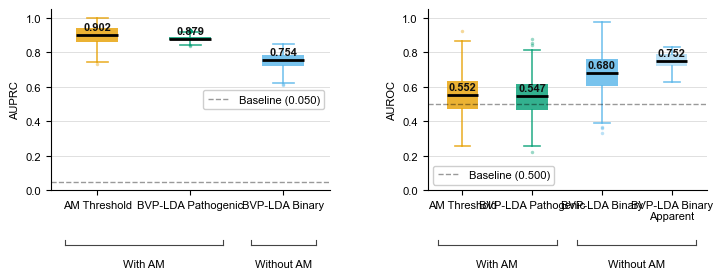

In [9]:
from matplotlib.transforms import blended_transform_factory

_pvh_data   = [arr1, arr3, arr2]
_pvh_labels = ['AM Threshold', 'BVP-LDA Pathogenic', 'BVP-LDA Binary']
_pvh_colors = [WONG['orange'], WONG['green'], WONG['sky_blue']]

_cvb_data   = [arr4, arr6, arr5, arr7]
_cvb_labels = ['AM Threshold', 'BVP-LDA Pathogenic', 'BVP-LDA Binary', 'BVP-LDA Binary\nApparent']
_cvb_colors = [WONG['orange'], WONG['green'], WONG['sky_blue'], WONG['sky_blue']]


def _draw_panel(ax, data, labels, colors, baseline, ylabel):
    for pos, (vals, color) in enumerate(zip(data, colors)):
        _apparent = (pos == 3 and len(data) == 4)
        bp = ax.boxplot(
            vals, positions=[pos], widths=0.45,
            patch_artist=True,
            medianprops=dict(color='black', linewidth=2.0),
        )
        box = bp['boxes'][0]
        box.set(facecolor=color, edgecolor='none',
                alpha=0.40 if _apparent else 0.80)
        if _apparent:
            box.set_hatch('//')
        for wi in [0, 1]:
            bp['whiskers'][wi].set(color=color, linewidth=1.2, alpha=0.80)
            bp['caps'][wi].set(color=color, linewidth=1.2, alpha=0.80)
        if bp['fliers']:
            bp['fliers'][0].set(markerfacecolor=color, markeredgecolor='none',
                                alpha=0.4, markersize=2.5)
        med = float(np.median(vals))
        ax.text(pos, med + 0.015, f'{med:.3f}',
                ha='center', va='bottom', fontsize=8,
                fontweight='bold', color='#111111')
    ax.axhline(baseline, color='k', lw=1, ls='--', alpha=0.4,
               label=f'Baseline ({baseline:.3f})')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, frameon=True, framealpha=0.95, edgecolor='#CCCCCC')
    ax.grid(axis='y', color='#E0E0E0', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


def _add_spanner(ax, x0, x1, label, y_bar=-0.30, y_label=-0.38):
    trans = blended_transform_factory(ax.transData, ax.transAxes)
    pad, tick_h = 0.35, 0.025
    lx, rx = x0 - pad, x1 + pad
    ax.plot([lx, rx], [y_bar, y_bar],
            transform=trans, color='#444444', lw=0.8, clip_on=False)
    ax.plot([lx, lx], [y_bar + tick_h, y_bar],
            transform=trans, color='#444444', lw=0.8, clip_on=False)
    ax.plot([rx, rx], [y_bar + tick_h, y_bar],
            transform=trans, color='#444444', lw=0.8, clip_on=False)
    ax.text((x0 + x1) / 2, y_label, label,
            ha='center', va='top', fontsize=8,
            transform=trans, clip_on=False)


# 183 mm figure width (e.g. journal double-column), height scaled to match
# the original 12:4.5 in aspect ratio; all text set to Helvetica 8pt
# (falls back to Arial, Helvetica's metric clone, on systems without it installed).
MM_TO_IN     = 1 / 25.4
_FIG_W_IN    = 183 * MM_TO_IN
_FIG_H_IN    = _FIG_W_IN * (4.5 / 12)

with plt.rc_context({
    'font.family':     'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'Nimbus Sans', 'DejaVu Sans'],
    'font.size':       8,
}):
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(_FIG_W_IN, _FIG_H_IN))
    fig.patch.set_facecolor('white')
    fig.subplots_adjust(wspace=0.35, left=0.07, right=0.98, top=0.95, bottom=0.28)

    _draw_panel(ax_left,  _pvh_data, _pvh_labels, _pvh_colors, _prev_g_h, 'AUPRC')
    _draw_panel(ax_right, _cvb_data, _cvb_labels, _cvb_colors, 0.5,       'AUROC')

    _add_spanner(ax_left,  0, 1, 'With AM')
    _add_spanner(ax_left,  2, 2, 'Without AM')
    _add_spanner(ax_right, 0, 1, 'With AM')
    _add_spanner(ax_right, 2, 3, 'Without AM')

    _figname = 'KO7_model_overview'
    plt.savefig(out_dir / f'{_figname}.pdf', dpi=300, bbox_inches='tight')
    plt.savefig(out_dir / f'{_figname}.png', dpi=300, bbox_inches='tight')
    with plt.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out_dir / f'{_figname}.svg', bbox_inches='tight')
    print('Saved to', out_dir.resolve())
    plt.show()

## 8. Statistical Significance Analysis

**Caveat — resampled CV and non-independence.**
The per-fold metric arrays (n = 500 each for rows 1–6) are products of resampling a single cohort:
folds within a draw share training data, and draws overlap via subagging / bootstrapping.
Consequently, naive rank-sum p-values are **anti-conservative** (Dietterich 1998; Nadeau & Bengio 2003)
and should not be interpreted as out-of-sample generalisation evidence.

**Approach:**
1. **Per-draw aggregation** — average 5 folds per draw → 100 values per model, reducing within-draw dependence.
2. **Effect sizes first** — median difference with bootstrap 95 % CI and rank-biserial correlation *r*.
3. **Nadeau–Bengio corrected resampled *t*-test** for paired comparisons (same CV folds per draw) — the principled test for repeated *k*-fold CV.
4. **Mann–Whitney *U*** for unpaired (cross-pipeline) comparisons — descriptive only.
5. **Holm–Bonferroni** correction within each task family.
6. **Supplementary** — raw fold-level tests (n = 500) as a sensitivity check, with caveat.

### 8.1 Per-Draw Aggregation

In [10]:
from scipy import stats as sp_stats

N_DRAWS = 100
N_FOLDS = 5

SHORT = [
    'PvH Threshold', 'PvH LDA Bin', 'PvH LDA Path',
    'CvB Threshold', 'CvB LDA Bin', 'CvB LDA Path', 'CvB LDA Bin (app)',
]

draw_means = {}
for lbl, arr in zip(SHORT, ARRAYS):
    if len(arr) == N_DRAWS * N_FOLDS:
        draw_means[lbl] = arr.reshape(N_DRAWS, N_FOLDS).mean(axis=1)
    else:
        draw_means[lbl] = arr.copy()

for lbl, dm in draw_means.items():
    print(f'{lbl:<25s}  n={len(dm):>3d}  median={np.median(dm):.4f}')

PvH Threshold              n=100  median=0.8983
PvH LDA Bin                n=100  median=0.7532
PvH LDA Path               n=100  median=0.8850
CvB Threshold              n=100  median=0.5598
CvB LDA Bin                n=100  median=0.6822
CvB LDA Path               n=100  median=0.5394
CvB LDA Bin (app)          n=100  median=0.7519


### 8.2 Effect Sizes — Pairwise & vs Baseline

In [11]:
def bootstrap_median_diff_ci(a, b, paired, n_boot=10_000, seed=42):
    """Bootstrap 95% CI of median(a) - median(b)."""
    rng = np.random.default_rng(seed)
    na, nb = len(a), len(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        if paired:
            idx = rng.integers(0, na, size=na)
            diffs[i] = np.median(a[idx]) - np.median(b[idx])
        else:
            idx_a = rng.integers(0, na, size=na)
            idx_b = rng.integers(0, nb, size=nb)
            diffs[i] = np.median(a[idx_a]) - np.median(b[idx_b])
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

def rank_biserial_paired(a, b):
    """Rank-biserial r for paired Wilcoxon signed-rank (effect size)."""
    d = a - b
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return 0.0
    ranks = sp_stats.rankdata(np.abs(d))
    r_plus = ranks[d > 0].sum()
    return float(r_plus / ranks.sum() * 2 - 1)

def rank_biserial_unpaired(a, b):
    """Rank-biserial r for Mann-Whitney U (effect size)."""
    u_stat, _ = sp_stats.mannwhitneyu(a, b, alternative='two-sided')
    n1, n2 = len(a), len(b)
    return float(2 * u_stat / (n1 * n2) - 1)

# ── Define all pairwise comparisons ──────────────────────────────────────────
PVH_PAIRS = [
    ('PvH Threshold', 'PvH LDA Bin',  'unpaired'),
    ('PvH Threshold', 'PvH LDA Path', 'unpaired'),
    ('PvH LDA Bin',   'PvH LDA Path', 'paired'),
]
CVB_PAIRS = [
    ('CvB Threshold', 'CvB LDA Bin',       'unpaired'),
    ('CvB Threshold', 'CvB LDA Path',      'unpaired'),
    ('CvB Threshold', 'CvB LDA Bin (app)', 'unpaired'),
    ('CvB LDA Bin',   'CvB LDA Path',      'paired'),
    ('CvB LDA Bin',   'CvB LDA Bin (app)', 'paired'),
    ('CvB LDA Path',  'CvB LDA Bin (app)', 'paired'),
]

rows_effect = []
for pairs, task in [(PVH_PAIRS, 'PvH'), (CVB_PAIRS, 'CvB')]:
    for la, lb, kind in pairs:
        a, b = draw_means[la], draw_means[lb]
        med_diff = float(np.median(a) - np.median(b))
        ci_lo, ci_hi = bootstrap_median_diff_ci(a, b, paired=(kind == 'paired'))
        r = rank_biserial_paired(a, b) if kind == 'paired' else rank_biserial_unpaired(a, b)
        rows_effect.append({
            'Task': task, 'A': la, 'B': lb, 'Pairing': kind,
            'Med_diff': med_diff, 'CI_lo': ci_lo, 'CI_hi': ci_hi, 'r_rb': r,
        })

df_effect = pl.DataFrame(rows_effect)
display(df_effect.select(
    'Task', 'A', 'B', 'Pairing',
    pl.col('Med_diff').round(4).alias('Δ Median'),
    pl.format('[{}, {}]', pl.col('CI_lo').round(4), pl.col('CI_hi').round(4)).alias('95% CI'),
    pl.col('r_rb').round(3).alias('r (rank-bis)'),
))

Task,A,B,Pairing,Δ Median,95% CI,r (rank-bis)
str,str,str,str,f64,str,f64
"""PvH""","""PvH Threshold""","""PvH LDA Bin""","""unpaired""",0.1451,"""[0.1393, 0.1535]""",1.0
"""PvH""","""PvH Threshold""","""PvH LDA Path""","""unpaired""",0.0133,"""[0.0092, 0.0179]""",0.588
"""PvH""","""PvH LDA Bin""","""PvH LDA Path""","""paired""",-0.1318,"""[-0.1382, -0.1276]""",-1.0
"""CvB""","""CvB Threshold""","""CvB LDA Bin""","""unpaired""",-0.1224,"""[-0.152, -0.1012]""",-0.84
"""CvB""","""CvB Threshold""","""CvB LDA Path""","""unpaired""",0.0205,"""[-0.0057, 0.0349]""",0.129
"""CvB""","""CvB Threshold""","""CvB LDA Bin (app)""","""unpaired""",-0.1921,"""[-0.2203, -0.1759]""",-0.992
"""CvB""","""CvB LDA Bin""","""CvB LDA Path""","""paired""",0.1429,"""[0.1216, 0.1622]""",0.979
"""CvB""","""CvB LDA Bin""","""CvB LDA Bin (app)""","""paired""",-0.0696,"""[-0.0821, -0.0583]""",-1.0
"""CvB""","""CvB LDA Path""","""CvB LDA Bin (app)""","""paired""",-0.2125,"""[-0.231, -0.1963]""",-1.0


In [12]:
# ── Each model vs its task baseline ───────────────────────────────────────────
BASELINES = {
    'PvH Threshold': _prev_g_h, 'PvH LDA Bin': _prev_g_h, 'PvH LDA Path': _prev_g_h,
    'CvB Threshold': 0.5, 'CvB LDA Bin': 0.5, 'CvB LDA Path': 0.5, 'CvB LDA Bin (app)': 0.5,
}

rows_base = []
for lbl, dm in draw_means.items():
    bl = BASELINES[lbl]
    exceed = (dm > bl).sum()
    n = len(dm)
    ci_binom = sp_stats.binom.interval(0.95, n, exceed / n)
    rows_base.append({
        'Model': lbl,
        'Baseline': bl,
        'Med_diff': float(np.median(dm) - bl),
        'Exceed': f'{exceed}/{n}',
        'Binom_CI': f'[{ci_binom[0]/n:.2f}, {ci_binom[1]/n:.2f}]',
    })

display(pl.DataFrame(rows_base))

Model,Baseline,Med_diff,Exceed,Binom_CI
str,f64,f64,str,str
"""PvH Threshold""",0.049852,0.848442,"""100/100""","""[1.00, 1.00]"""
"""PvH LDA Bin""",0.049852,0.703337,"""100/100""","""[1.00, 1.00]"""
"""PvH LDA Path""",0.049852,0.835099,"""100/100""","""[1.00, 1.00]"""
"""CvB Threshold""",0.5,0.059817,"""84/100""","""[0.77, 0.91]"""
"""CvB LDA Bin""",0.5,0.182237,"""100/100""","""[1.00, 1.00]"""
"""CvB LDA Path""",0.5,0.039354,"""79/100""","""[0.71, 0.87]"""
"""CvB LDA Bin (app)""",0.5,0.251872,"""100/100""","""[1.00, 1.00]"""


### 8.3 Nadeau–Bengio Corrected Resampled *t*-Test (Paired Comparisons)

For classifiers evaluated on **the same CV folds per draw**, the corrected *t*-test (Nadeau & Bengio 2003) inflates the variance to account for train/test overlap:

$$t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{r \cdot k} + \frac{n_\text{test}}{n_\text{train}}\right) \hat{\sigma}^2_d}}, \quad \text{df} = r \cdot k - 1$$

This is the principled alternative to naive paired Wilcoxon on repeated CV folds.

In [13]:
def nadeau_bengio_t(arr_a, arr_b, r, k):
    """Corrected resampled t-test (Nadeau & Bengio 2003).

    Parameters
    ----------
    arr_a, arr_b : arrays of per-fold (or per-draw) metric values, length r*k.
    r : number of repetitions (draws).
    k : number of CV folds per draw.

    Returns (t_stat, p_value, df).
    """
    d = arr_a - arr_b
    d_bar = d.mean()
    s2 = d.var(ddof=1)
    n_test_over_n_train = 1.0 / (k - 1) if k > 1 else 1.0
    denom = np.sqrt((1.0 / (r * k) + n_test_over_n_train) * s2)
    if denom == 0:
        return 0.0, 1.0, r * k - 1
    t_stat = d_bar / denom
    df = r * k - 1
    p_val = float(2 * sp_stats.t.sf(np.abs(t_stat), df))
    return float(t_stat), p_val, df

# ── Paired comparisons: same CV folds per draw ──────────────────────────────
# PvH: arr2 ↔ arr3 (KO6_3, fixed folds, 100×5)
# CvB: arr5 ↔ arr6 (KO6_4, per-draw folds, 100×5)
# CvB: arr5 ↔ arr7, arr6 ↔ arr7 (same bootstrap draws; arr7 has no fold structure
#       → compare at draw level: r=100, k=1)

NB_TESTS = [
    ('PvH', 'PvH LDA Bin',        'PvH LDA Path',       arr2, arr3, 100, 5),
    ('CvB', 'CvB LDA Bin',        'CvB LDA Path',       arr5, arr6, 100, 5),
    ('CvB', 'CvB LDA Bin',        'CvB LDA Bin (app)',
     draw_means['CvB LDA Bin'], draw_means['CvB LDA Bin (app)'], 100, 1),
    ('CvB', 'CvB LDA Path',       'CvB LDA Bin (app)',
     draw_means['CvB LDA Path'], draw_means['CvB LDA Bin (app)'], 100, 1),
]

rows_nb = []
for task, la, lb, a, b, r, k in NB_TESTS:
    t_stat, p_val, df = nadeau_bengio_t(a, b, r, k)
    rows_nb.append({
        'Task': task, 'A': la, 'B': lb,
        'r': r, 'k': k,
        't': round(t_stat, 3), 'df': df, 'p_raw': p_val,
    })

df_nb = pl.DataFrame(rows_nb)
display(df_nb.with_columns(
    pl.col('p_raw').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (raw)'),
))

Task,A,B,r,k,t,df,p_raw,p (raw)
str,str,str,i64,i64,f64,i64,f64,str
"""PvH""","""PvH LDA Bin""","""PvH LDA Path""",100,5,-6.65,499,7.6977e-11,"""7.70e-11"""
"""CvB""","""CvB LDA Bin""","""CvB LDA Path""",100,5,1.841,499,0.066213,"""6.62e-02"""
"""CvB""","""CvB LDA Bin""","""CvB LDA Bin (app)""",100,1,-2.728,99,0.007538,"""7.54e-03"""
"""CvB""","""CvB LDA Path""","""CvB LDA Bin (app)""",100,1,-2.897,99,0.004643,"""4.64e-03"""


### 8.4 Descriptive Pairwise Tests (Cross-Pipeline, Unpaired)

Mann–Whitney *U* on per-draw means for comparisons between KO5 (AM thresholding) and KO6 (LDA) pipelines. These use different resampling schemes and are therefore **unpaired**.

> **Caveat:** these p-values reflect resampling stability on one cohort, not out-of-sample significance.

In [14]:
UNPAIRED = [
    ('PvH', 'PvH Threshold', 'PvH LDA Bin'),
    ('PvH', 'PvH Threshold', 'PvH LDA Path'),
    ('CvB', 'CvB Threshold', 'CvB LDA Bin'),
    ('CvB', 'CvB Threshold', 'CvB LDA Path'),
    ('CvB', 'CvB Threshold', 'CvB LDA Bin (app)'),
]

rows_mw = []
for task, la, lb in UNPAIRED:
    a, b = draw_means[la], draw_means[lb]
    u_stat, p_val = sp_stats.mannwhitneyu(a, b, alternative='two-sided')
    rows_mw.append({
        'Task': task, 'A': la, 'B': lb,
        'U': float(u_stat), 'p_raw': p_val,
    })

df_mw = pl.DataFrame(rows_mw)
display(df_mw.with_columns(
    pl.col('p_raw').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (raw)'),
))

Task,A,B,U,p_raw,p (raw)
str,str,str,f64,f64,str
"""PvH""","""PvH Threshold""","""PvH LDA Bin""",10000.0,2.5621e-34,"""2.56e-34"""
"""PvH""","""PvH Threshold""","""PvH LDA Path""",7942.0,6.6120e-13,"""6.61e-13"""
"""CvB""","""CvB Threshold""","""CvB LDA Bin""",800.0,1.0559e-24,"""1.06e-24"""
"""CvB""","""CvB Threshold""","""CvB LDA Path""",5647.0,0.114187,"""1.14e-01"""
"""CvB""","""CvB Threshold""","""CvB LDA Bin (app)""",42.0,9.0016e-34,"""9.00e-34"""


### 8.5 Baseline Tests (One-Sample Wilcoxon Signed-Rank)

In [15]:
rows_bl = []
for lbl, dm in draw_means.items():
    bl = BASELINES[lbl]
    shifted = dm - bl
    shifted = shifted[shifted != 0]
    if len(shifted) > 0:
        stat, p_val = sp_stats.wilcoxon(shifted, alternative='greater')
    else:
        stat, p_val = 0.0, 1.0
    task = 'PvH' if lbl.startswith('PvH') else 'CvB'
    rows_bl.append({
        'Task': task, 'Model': lbl, 'Baseline': round(bl, 4),
        'W': float(stat), 'p_raw': p_val,
    })

df_bl = pl.DataFrame(rows_bl)
display(df_bl.with_columns(
    pl.col('p_raw').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (raw)'),
))

Task,Model,Baseline,W,p_raw,p (raw)
str,str,f64,f64,f64,str
"""PvH""","""PvH Threshold""",0.0499,5050.0,1.9483e-18,"""1.95e-18"""
"""PvH""","""PvH LDA Bin""",0.0499,5050.0,1.9483e-18,"""1.95e-18"""
"""PvH""","""PvH LDA Path""",0.0499,5050.0,1.9483e-18,"""1.95e-18"""
"""CvB""","""CvB Threshold""",0.5,4648.0,1.4435e-13,"""1.44e-13"""
"""CvB""","""CvB LDA Bin""",0.5,5050.0,1.9483e-18,"""1.95e-18"""
"""CvB""","""CvB LDA Path""",0.5,4356.0,1.5313e-10,"""1.53e-10"""
"""CvB""","""CvB LDA Bin (app)""",0.5,5050.0,1.9481e-18,"""1.95e-18"""


### 8.6–8.7 Holm–Bonferroni Correction & Summary Table

Multiple comparison correction applied **within each task family** (PvH, CvB).

In [16]:
def holm_bonferroni(p_values):
    """Return Holm–Bonferroni adjusted p-values."""
    m = len(p_values)
    idx = np.argsort(p_values)
    adjusted = np.empty(m)
    cummax = 0.0
    for rank, i in enumerate(idx):
        adj = p_values[i] * (m - rank)
        cummax = max(cummax, adj)
        adjusted[i] = min(cummax, 1.0)
    return adjusted

def _stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

# ── Collect all tests into one table ─────────────────────────────────────────
all_rows = []

# Nadeau–Bengio (paired)
for row in rows_nb:
    eff = [r for r in rows_effect if r['A'] == row['A'] and r['B'] == row['B']]
    e = eff[0] if eff else {}
    all_rows.append({
        'Task': row['Task'],
        'Comparison': f"{row['A']}  vs  {row['B']}",
        'Test': f"NB corrected t (r={row['r']}, k={row['k']})",
        'Δ Median': e.get('Med_diff', None),
        '95% CI': f"[{e['CI_lo']:.4f}, {e['CI_hi']:.4f}]" if e else '',
        'r (rank-bis)': e.get('r_rb', None),
        'p_raw': row['p_raw'],
    })

# Mann-Whitney (unpaired)
for row in rows_mw:
    eff = [r for r in rows_effect if r['A'] == row['A'] and r['B'] == row['B']]
    e = eff[0] if eff else {}
    all_rows.append({
        'Task': row['Task'],
        'Comparison': f"{row['A']}  vs  {row['B']}",
        'Test': 'Mann–Whitney U (descriptive)',
        'Δ Median': e.get('Med_diff', None),
        '95% CI': f"[{e['CI_lo']:.4f}, {e['CI_hi']:.4f}]" if e else '',
        'r (rank-bis)': e.get('r_rb', None),
        'p_raw': row['p_raw'],
    })

# Baseline (one-sample Wilcoxon)
for row in rows_bl:
    all_rows.append({
        'Task': row['Task'],
        'Comparison': f"{row['Model']}  vs  baseline ({row['Baseline']})",
        'Test': 'One-sample Wilcoxon (descriptive)',
        'Δ Median': None,
        '95% CI': '',
        'r (rank-bis)': None,
        'p_raw': row['p_raw'],
    })

df_all = pl.DataFrame(all_rows)

# ── Holm–Bonferroni per task family ──────────────────────────────────────────
adjusted = np.empty(len(df_all))
for task in ['PvH', 'CvB']:
    mask = (df_all['Task'] == task).to_numpy()
    raw = df_all.filter(pl.col('Task') == task)['p_raw'].to_numpy()
    adj = holm_bonferroni(raw)
    adjusted[mask] = adj

df_all = df_all.with_columns(
    pl.Series('p_adj', adjusted),
)
df_all = df_all.with_columns(
    pl.col('p_adj').map_elements(lambda p: _stars(p), return_dtype=pl.Utf8).alias('Sig'),
)

# ── Display ──────────────────────────────────────────────────────────────────
pl.Config.set_tbl_rows(-1)
display(df_all.select(
    'Task', 'Comparison', 'Test',
    pl.col('Δ Median').round(4),
    '95% CI',
    pl.col('r (rank-bis)').round(3),
    pl.col('p_raw').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (raw)'),
    pl.col('p_adj').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (Holm)'),
    'Sig',
))

Task,Comparison,Test,Δ Median,95% CI,r (rank-bis),p (raw),p (Holm),Sig
str,str,str,f64,str,f64,str,str,str
"""PvH""","""PvH LDA Bin vs PvH LDA Path""","""NB corrected t (r=100, k=5)""",-0.1318,"""[-0.1382, -0.1276]""",-1.0,"""7.70e-11""","""7.70e-11""","""***"""
"""CvB""","""CvB LDA Bin vs CvB LDA Path""","""NB corrected t (r=100, k=5)""",0.1429,"""[0.1216, 0.1622]""",0.979,"""6.62e-02""","""1.32e-01""","""ns"""
"""CvB""","""CvB LDA Bin vs CvB LDA Bin (…","""NB corrected t (r=100, k=1)""",-0.0696,"""[-0.0821, -0.0583]""",-1.0,"""7.54e-03""","""2.26e-02""","""*"""
"""CvB""","""CvB LDA Path vs CvB LDA Bin …","""NB corrected t (r=100, k=1)""",-0.2125,"""[-0.2310, -0.1963]""",-1.0,"""4.64e-03""","""1.86e-02""","""*"""
"""PvH""","""PvH Threshold vs PvH LDA Bin""","""Mann–Whitney U (descriptive)""",0.1451,"""[0.1393, 0.1535]""",1.0,"""2.56e-34""","""1.54e-33""","""***"""
"""PvH""","""PvH Threshold vs PvH LDA Pat…","""Mann–Whitney U (descriptive)""",0.0133,"""[0.0092, 0.0179]""",0.588,"""6.61e-13""","""1.32e-12""","""***"""
"""CvB""","""CvB Threshold vs CvB LDA Bin""","""Mann–Whitney U (descriptive)""",-0.1224,"""[-0.1520, -0.1012]""",-0.84,"""1.06e-24""","""9.50e-24""","""***"""
"""CvB""","""CvB Threshold vs CvB LDA Pat…","""Mann–Whitney U (descriptive)""",0.0205,"""[-0.0057, 0.0349]""",0.129,"""1.14e-01""","""1.32e-01""","""ns"""
"""CvB""","""CvB Threshold vs CvB LDA Bin…","""Mann–Whitney U (descriptive)""",-0.1921,"""[-0.2203, -0.1759]""",-0.992,"""9.00e-34""","""9.00e-33""","""***"""


### 8.8 Supplementary — Raw Fold-Level Tests (n = 500)

Sensitivity check using all 500 per-fold values instead of 100 per-draw means.

> **Caveat:** these 500 values are **not independent** — folds within a draw share training data and draws overlap via subagging/bootstrapping. P-values here are heavily anti-conservative and should be interpreted as a lower bound on significance, not as generalization evidence.

In [ ]:
# ── Raw fold-level: paired Wilcoxon for same-pipeline, Mann-Whitney for cross-pipeline ─
RAW_PAIRED = [
    ('PvH', 'PvH LDA Bin',  'PvH LDA Path',      arr2, arr3),
    ('CvB', 'CvB LDA Bin',  'CvB LDA Path',       arr5, arr6),
]
RAW_UNPAIRED = [
    ('PvH', 'PvH Threshold', 'PvH LDA Bin',       arr1, arr2),
    ('PvH', 'PvH Threshold', 'PvH LDA Path',      arr1, arr3),
    ('CvB', 'CvB Threshold', 'CvB LDA Bin',       arr4, arr5),
    ('CvB', 'CvB Threshold', 'CvB LDA Path',      arr4, arr6),
    ('CvB', 'CvB Threshold', 'CvB LDA Bin (app)', arr4, arr7),
]
# arr7 vs arr5/arr6 at raw level: arr7 is n=100 (no folds), arr5/arr6 are n=500 → unpaired
RAW_UNPAIRED += [
    ('CvB', 'CvB LDA Bin',  'CvB LDA Bin (app)',  arr5, arr7),
    ('CvB', 'CvB LDA Path', 'CvB LDA Bin (app)',  arr6, arr7),
]

rows_raw = []
for task, la, lb, a, b in RAW_PAIRED:
    stat, p = sp_stats.wilcoxon(a, b, alternative='two-sided')
    rows_raw.append({
        'Task': task, 'Comparison': f'{la}  vs  {lb}',
        'Test': f'Wilcoxon signed-rank (n={len(a)})', 'p_raw': p,
    })
for task, la, lb, a, b in RAW_UNPAIRED:
    stat, p = sp_stats.mannwhitneyu(a, b, alternative='two-sided')
    rows_raw.append({
        'Task': task, 'Comparison': f'{la}  vs  {lb}',
        'Test': f'Mann–Whitney U (n={len(a)} vs {len(b)})', 'p_raw': p,
    })

# Baseline — raw fold level
for lbl, arr_raw in zip(SHORT, ARRAYS):
    bl = BASELINES[lbl]
    shifted = arr_raw - bl
    shifted = shifted[shifted != 0]
    if len(shifted) > 0:
        _, p = sp_stats.wilcoxon(shifted, alternative='greater')
    else:
        p = 1.0
    task = 'PvH' if lbl.startswith('PvH') else 'CvB'
    rows_raw.append({
        'Task': task, 'Comparison': f'{lbl}  vs  baseline ({bl:.4f})',
        'Test': f'One-sample Wilcoxon (n={len(arr_raw)})', 'p_raw': p,
    })

df_raw = pl.DataFrame(rows_raw)

# Holm per task
adj_raw = np.empty(len(df_raw))
for task in ['PvH', 'CvB']:
    mask = (df_raw['Task'] == task).to_numpy()
    raw_p = df_raw.filter(pl.col('Task') == task)['p_raw'].to_numpy()
    adj_raw[mask] = holm_bonferroni(raw_p)

df_raw = df_raw.with_columns(pl.Series('p_adj', adj_raw))
df_raw = df_raw.with_columns(
    pl.col('p_adj').map_elements(lambda p: _stars(p), return_dtype=pl.Utf8).alias('Sig'),
)

display(df_raw.select(
    'Task', 'Comparison', 'Test',
    pl.col('p_raw').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (raw)'),
    pl.col('p_adj').map_elements(lambda p: f'{p:.2e}', return_dtype=pl.Utf8).alias('p (Holm)'),
    'Sig',
))